Do large moves cluster in time?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

from quantlab.data_loader import load_prices
from quantlab.returns import log_returns
from quantlab.diagnostics import autocorr_table, rolling_vol

r = log_returns(load_prices())
print(r.shape)

(6537, 26)


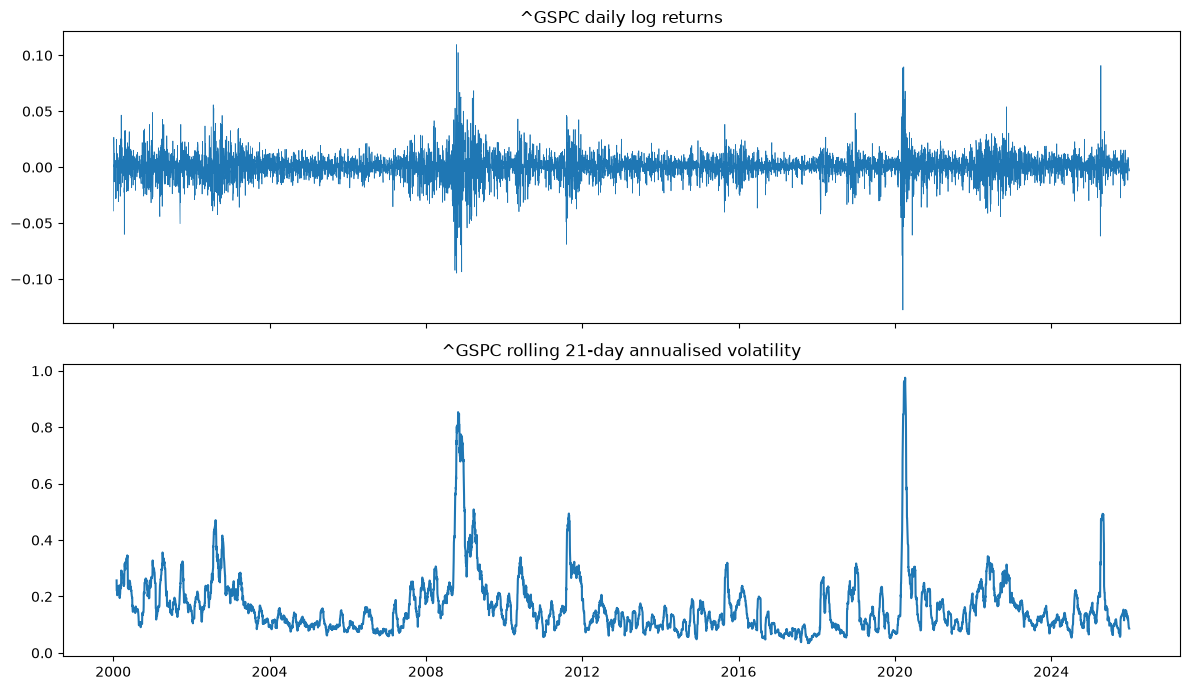

In [2]:
vol = rolling_vol(r, window=21)

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(r["^GSPC"], linewidth=0.5)
ax[0].set_title("^GSPC daily log returns")
ax[1].plot(vol["^GSPC"])
ax[1].set_title("^GSPC rolling 21-day annualised volatility")
plt.tight_layout()
plt.show()

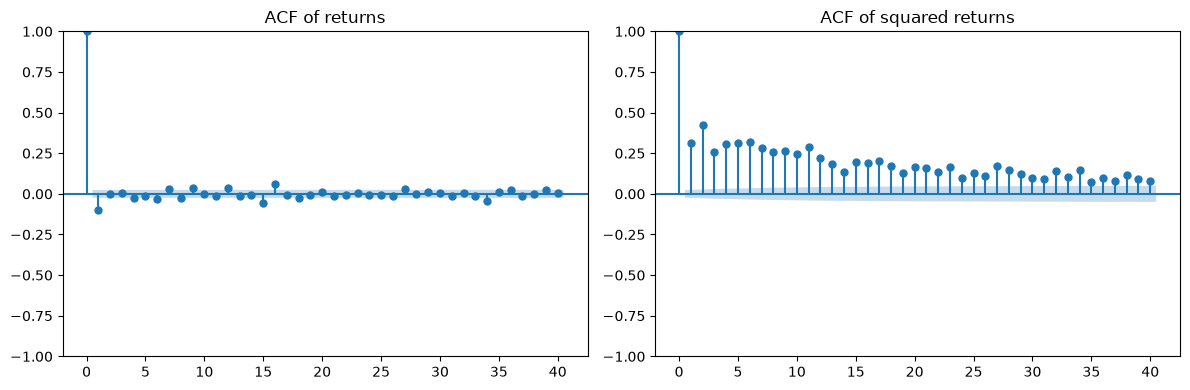

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(r["^GSPC"], lags=40, ax=ax[0], title="ACF of returns")
plot_acf(r["^GSPC"] ** 2, lags=40, ax=ax[1], title="ACF of squared returns")
plt.tight_layout()
plt.show()

In [4]:
ac = autocorr_table(r)
ac.round(4).sort_values("acf_sq", ascending=False)

,acf_ret,acf_sq,lb_p_ret,lb_p_sq
JPM,-0.0831,0.3542,0.0000,0.0000
BAC,-0.0141,0.3320,0.0000,0.0000
PEP,-0.0933,0.3304,0.0000,0.0000
^GSPC,-0.0998,0.3131,0.0000,0.0000
XOM,-0.0699,0.2633,0.0000,0.0000
KO,-0.0195,0.2406,0.0005,0.0000
AMGN,-0.0534,0.2397,0.0000,0.0000
WFC,-0.0893,0.2352,0.0000,0.0000
NEE,-0.0441,0.2352,0.0000,0.0000
GILD,-0.0363,0.2239,0.0000,0.0000


In [5]:
print("Returns with Ljung-Box p < 0.05:", int((ac["lb_p_ret"] < 0.05).sum()), "of", len(ac))
print("Squared returns with Ljung-Box p < 0.05:", int((ac["lb_p_sq"] < 0.05).sum()), "of", len(ac))
print("Mean lag-1 ACF of returns:", ac["acf_ret"].mean().round(3))
print("Mean lag-1 ACF of squared returns:", ac["acf_sq"].mean().round(3))

Returns with Ljung-Box p < 0.05: 25 of 26
Squared returns with Ljung-Box p < 0.05: 26 of 26
Mean lag-1 ACF of returns: -0.049
Mean lag-1 ACF of squared returns: 0.193


## Conclusions

**1. Returns.** The lag-1 autocorrelation of returns is small for every ticker. The average is -0.049 and the largest in size is -0.100 (^GSPC). With 6,537 observations the 95% band around zero is about ±0.024, so Ljung-Box flags 25 of 26 series as statistically significant (only CAT, p = 0.054, is not). But a correlation of -0.05 means yesterday's return explains about 0.25% of today's variance (0.05² = 0.0025), so it is practically useless for forecasting direction. The sign is slightly negative, meaning a small tendency for a rise to be followed by a slight fall. Daily direction is close to unpredictable.

**2. Squared returns.** This is where the structure is. The average lag-1 autocorrelation of squared returns is 0.193, about four times the size (and the opposite sign) of the one for returns. All 26 of 26 series have a Ljung-Box p-value below 0.05, and for 25 of them it is below 0.0001. The strongest are JPM (0.354), BAC (0.332), PEP (0.330) and ^GSPC (0.313). The weakest are AAPL (0.027) and PG (0.047). These are the same two tickers with the huge kurtosis in notebook 01. A single enormous 2000 move dominates their squared returns, which hides the ordinary clustering in the rest of the sample. AAPL is still significant (p = 0.020).

**3. Episodes.** In the rolling-volatility plot, volatility is not constant. It jumps in a few episodes (the dot-com bust of 2000-02, the 2008-09 financial crisis, and March 2020 are the main ones) and stays elevated for weeks or months before decaying slowly, rather than reverting within days. Long calm stretches (for example 2005-06 and 2017) sit at low levels. Large moves cluster in time.

**4. Consequence for the covariance matrix.** A single covariance matrix over 26 years averages very different regimes: calm periods, where volatility is low, and crises, where it is high and correlations also tend to rise. The estimate depends on which window is used and on whether it includes a crisis, so it describes no period accurately. An optimiser using it will give different portfolios depending on the sample window. Next we measure how noisy these estimates are.